# Thresholding Test with the video by slicing the scan

## Gamma fitting of the background

Libraries and importation of the full image

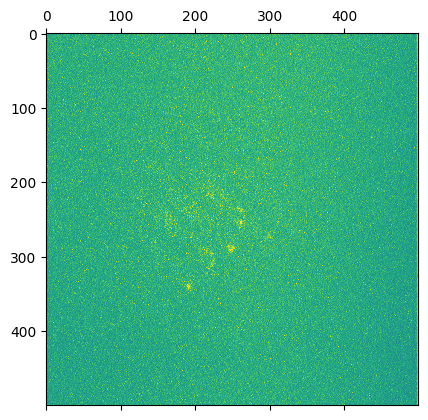

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import gamma as G
from scipy.special import polygamma
from scipy.stats import gamma,norm
from scipy.signal import convolve
from tifffile import imread
import os

pi=np.pi

scan=imread('video_different_bg.tif')
mat_full_image = np.array(scan, dtype='float16')
mat_full_image[np.where(mat_full_image == 0)] = 1 # prevent to have log of 0 
del(scan)
scan_shape=mat_full_image.shape

# mattest=mat2[100:200, 350:450] #background alone 
plt.matshow(mat_full_image[1], interpolation='none', cmap='viridis', vmax=np.quantile(mat_full_image, 0.999))
plt.show()

raveled_mat=np.ravel(mat_full_image[0]) #conversion the 2D array in a 1D array
raveled_mat_bg = raveled_mat[raveled_mat<700]

code to slice the scan into sub_image and then try to free memory when we need it

In [2]:
list = []
N = 4 # estimation of the number of emission frames of a molecule from the video, z direction
ker_depthsize = N
n = scan_shape[0] # number of frames from the scan
step = 400 # must be superior to the kernel size : 2*ker_depthsize+1
segmentation_list = range(0,n,step)
length = len(segmentation_list)
for i in range(length):
    if i != length-1:
        e = mat_full_image[segmentation_list[i]:segmentation_list[i+1]+2*ker_depthsize,:,:]
    else:
        e = mat_full_image[segmentation_list[i]:,:,:]
    num = str(i)
    filename = "sub_scan"+num+".npy"
    np.save(filename, e)
    del(e)

Gamma fitting function from scipy (the loc parameter must be 0.0 or floc=0.0)

In [3]:
alpha, loc, theta = gamma.fit(raveled_mat_bg, floc=0.0)

fitting of the background distribution

Fit result alpha=128.1664492041247, loc=0.0, theta=3.232421875


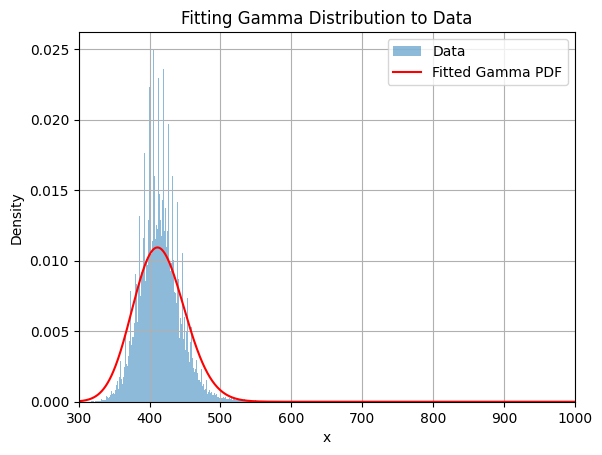

In [4]:
print(f"Fit result alpha={alpha}, loc={loc}, theta={theta}")

x = np.linspace(start=300, stop=1000, num=1000)
pdf_fitted = gamma.pdf(x, a=alpha, loc=loc, scale=theta)

# Plot histogram and fitted curve
plt.hist(raveled_mat_bg, bins='auto', density=True, alpha=0.5, label='Data')
plt.plot(x, pdf_fitted, 'r-', label='Fitted Gamma PDF')
plt.xlim([300,1000])
plt.title('Fitting Gamma Distribution to Data')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

# First thresholding attempt

## Image treatment :
- log transformation
- Concolution with a "Kernel" w_mn = a*s_mn

implementation of the Functions for the log/filter transformation

505.8 414.2 1.1465941905894346
(9, 7, 7)


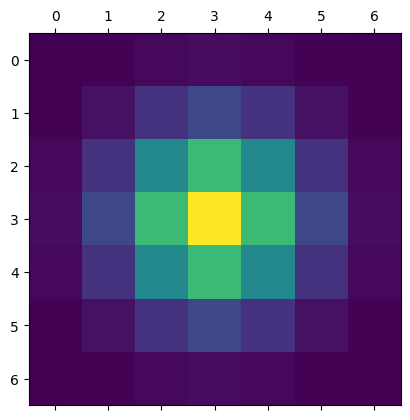

In [5]:
b=alpha*theta #background value: alpha*theta
a=np.max(mat_full_image[mat_full_image < np.quantile(mat_full_image, 0.99999)])-b
sigma=(1/2.3548)*2.7 # Calculated in the dedicated notebook
print(a,b,sigma)
gamma = 2.7 # fwhm Calculated in the dedicate dnotebook

def ln_transform(r_mn,theta):
    return np.log(r_mn, dtype="float16")-np.log(theta, dtype="float16") # modification of the dtype for memory/speed issues

def s_mn(l, m, n, sigma):
    return (1/pi)*(gamma/(l**2+gamma**2))*np.exp(-(m**2+n**2)/(2*sigma**2))/(2*pi*sigma**2)

def Kernel(a, L, T): 
    m = np.arange(-L,L+1).reshape(2*L+1,1)
    n = np.arange(-L,L+1).reshape(1,2*L+1)
    M = np.repeat(m, 2*L+1 ,1)
    N = np.repeat(n, 2*L+1 ,0)
    O = np.arange(-T, T+1)
    K = a * s_mn(O[:,np.newaxis,np.newaxis], M[np.newaxis,:], N[np.newaxis,:], sigma)
    return K

kernel_size = 3 # x and y directions

plt.matshow(Kernel(a, kernel_size, N)[0,:,:])
print(Kernel(a, kernel_size, N).shape)

Application of the functions on the full image

In [6]:
for i in range(length):
    num = str(i)
    filename = "sub_scan"+num+".npy"
    e = np.load(filename)
    log_transformed = ln_transform(e,theta)
    del(e)
    print("The size of the log transformed image is", log_transformed.shape)
    filename = "sub_filtered"+num+".npy"
    np.save(filename, log_transformed)
    del(log_transformed)
    
# dtype = log_transformed.dtype
# print(mat_full_image.dtype)
# print(dtype)

The size of the log transformed image is (408, 500, 500)
The size of the log transformed image is (408, 500, 500)
The size of the log transformed image is (408, 500, 500)
The size of the log transformed image is (408, 500, 500)
The size of the log transformed image is (400, 500, 500)


In [7]:
# start=0
# stop=5
# convolution_element = convolve(log_transformed[start:max(stop,2*N+1),:,:], Kernel(a, kernel_size, N), mode='valid')
# plt.matshow(convolution_element[0])
# print(log_transformed[start:stop,:,:].shape)
# print(convolution_element.shape)

segmentation of the convolution (result appended in a list)

In [8]:
ker = Kernel(a, kernel_size, N)
filtered_shape_list = []

for i in range(length):
    num = str(i)
    filename = "sub_filtered"+num+".npy"
    e = np.load(filename)
    convolution_element = convolve(e, ker, mode='valid')
    del(e)
    print("The size of the convolution element image is", convolution_element.shape)
    filtered_shape_list.append(convolution_element.shape)
    np.save(filename, convolution_element)
    del(convolution_element)

The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (392, 494, 494)


## Threshold

In [9]:
K=(1/(40*(2*N+1)))*np.array([[[1,1,1,1,1,1,1],
                              [1,1,1,1,1,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,1,1,1,1,1],
                              [1,1,1,1,1,1,1]]]*(2*N+1))

print(K.shape)

for i in range(length):
    num = str(i)
    filename = "sub_scan"+num+".npy"
    e = np.load(filename)
    bg_element = convolve(e, K, mode='valid')
    del(e)
    # os.remove(filename)
    print("The size of the bg element image is", bg_element.shape)
    
    h,i,j = filtered_shape_list[i]
    lh,li,lj = bg_element.shape
    dh=int((lh-h)/2)
    di=int((li-i)/2)
    dj=int((lj-j)/2)
    bg_resized_element=bg_element[dh:lh-dh,di:li-di,dj:lj-dj]
    print("The size of the bg element resized image is", bg_element.shape)
    filename = "sub_bg"+num+".npy"
    np.save(filename, bg_resized_element)
    del(bg_element)
    del(bg_resized_element)

def digamma(z):
    return polygamma(0,z)

def trigamma(z):
    return polygamma(1,z)

def inv_gauss(x):
    return norm.isf(x, loc=0, scale=1)

def tau(a, alpha, P_FP, L, T):
    """ 
    Parameters:
    * a: signal value
    * alpha: alpha matrix
    * P_FP: probability of false positive
    * L: kernel size
    * T: kernel freq size
    """
    W1 = Kernel(a, L, T)
    W2 = W1**2
    w1 = W1.sum()
    w2 = W2.sum()
    return np.sqrt(w2*trigamma(alpha))*inv_gauss(P_FP)+w1*digamma(alpha)

(9, 7, 7)
The size of the bg element image is (400, 494, 494)
The size of the bg element resized image is (400, 494, 494)
The size of the bg element image is (400, 494, 494)
The size of the bg element resized image is (400, 494, 494)
The size of the bg element image is (400, 494, 494)
The size of the bg element resized image is (400, 494, 494)
The size of the bg element image is (400, 494, 494)
The size of the bg element resized image is (400, 494, 494)
The size of the bg element image is (392, 494, 494)
The size of the bg element resized image is (392, 494, 494)


parameters of the thresholding (P_FP, Alpha)
and display of the Tau matrix

In [10]:
P_FP = 1e-6

for i in range(length):
    num = str(i)
    filename = "sub_bg"+num+".npy"
    e = np.load(filename)
    Alpha = e/theta
    tau_element = tau(a,Alpha, P_FP, kernel_size, N)
    del(e)
    os.remove(filename)
    print("The size of the convolution element image is", tau_element.shape)
    filename = "sub_tau"+num+".npy"
    np.save(filename, tau_element)
    del(tau_element)

The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (400, 494, 494)
The size of the convolution element image is (392, 494, 494)


Application of the thresholding on the full filtered image

In [11]:
for i in range(length):
    num = str(i)

    filename = "sub_filtered"+num+".npy"
    filtered = np.load(filename)
    # os.remove(filename)

    filename = "sub_tau"+num+".npy"
    tau = np.load(filename)
    os.remove(filename)

    T = filtered >= tau

    del(filtered)
    del(tau)
    filename = "sub_thresholded"+num+".npy"
    np.save(filename, T)
    del(T)